In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
from glob import glob
import IPython.display as ipd
import tensorflow as tf
from PIL import Image

/opt/conda/lib/python3.10/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.3
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
df = pd.read_csv("/kaggle/input/bird-song-data-set/bird_songs_metadata.csv")
df.head(10)

,id,genus,species,subspecies,name,recordist,country,location,latitude,longitude,altitude,sound_type,source_url,license,time,date,remarks,filename
0,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-0.wav
1,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-1.wav
2,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-4.wav
3,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-5.wav
4,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-6.wav
5,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-8.wav
6,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-9.wav
7,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-11.wav
8,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-14.wav
9,557838,Thryomanes,bewickii,NaN,Bewick's Wren,Whitney Neufeld-Kaiser,United States,"Arlington, Snohomish County, Washington",48.0708,-122.1006,100,"adult, sex uncertain, song",//www.xeno-canto.org/557838,//creativecommons.org/licenses/by-nc-sa/4.0/,11:51,2020-03-14,"Recorded with Voice Record Pro on iPhone7, nor...",557838-15.wav


In [3]:
class_names = df["name"].unique()
print(class_names)

["Bewick's Wren" 'Northern Mockingbird' 'American Robin' 'Song Sparrow'
 'Northern Cardinal']


In [4]:
df["name"].value_counts()

name
Song Sparrow            1256
Northern Mockingbird    1182
Northern Cardinal       1074
American Robin          1017
Bewick's Wren            893
Name: count, dtype: int64

<BarContainer object of 5 artists>

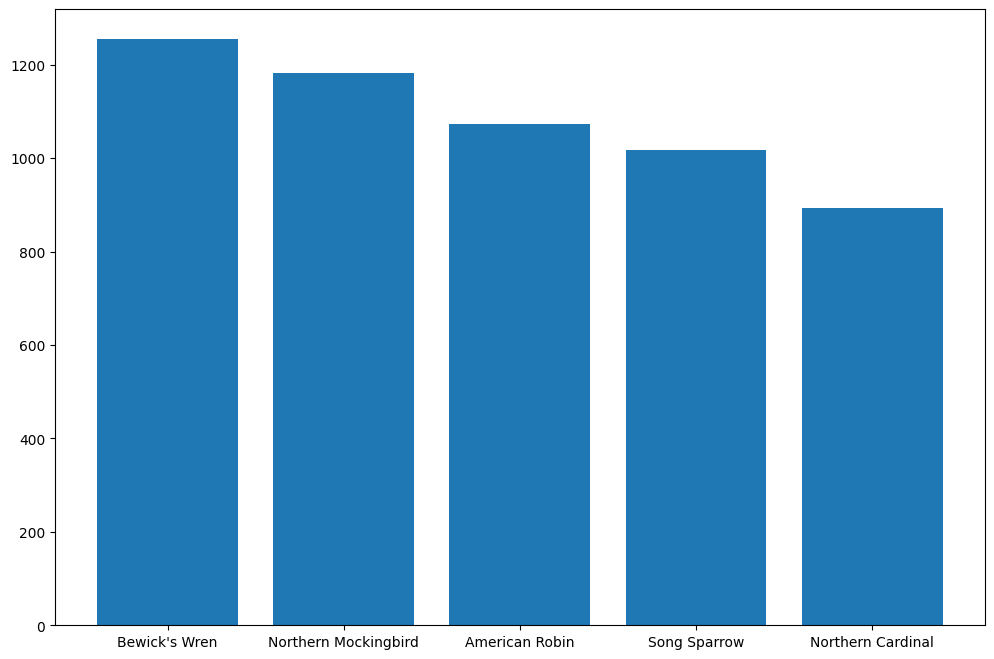

In [5]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.bar(df["name"].unique(), df["name"].value_counts())

Getting all the WAV files

In [6]:
path_to_wav = "/kaggle/input/bird-song-data-set/wavfiles/"
datafiles = glob(path_to_wav + "*")

Function to generate a spectrogram

In [7]:
def generate_spectrogram(file_audio, identifier):
    audio_data, sample_rate = librosa.load(path_to_wav + file_audio)
    spec_mel = librosa.feature.melspectrogram(y=audio_data, sr=sample_rate)
    spec_mel = librosa.power_to_db(spec_mel, ref=np.max)
    figure, axis = plt.subplots(figsize=(15, 5))
    axis.set_title("Mel Spectrogram")
    plt.suptitle(identifier)
    librosa.display.specshow(spec_mel, x_axis='time', y_axis='log', ax=axis)
    return ipd.Audio(path_to_wav + file_audio, rate=sample_rate)

Generating random spectrogram

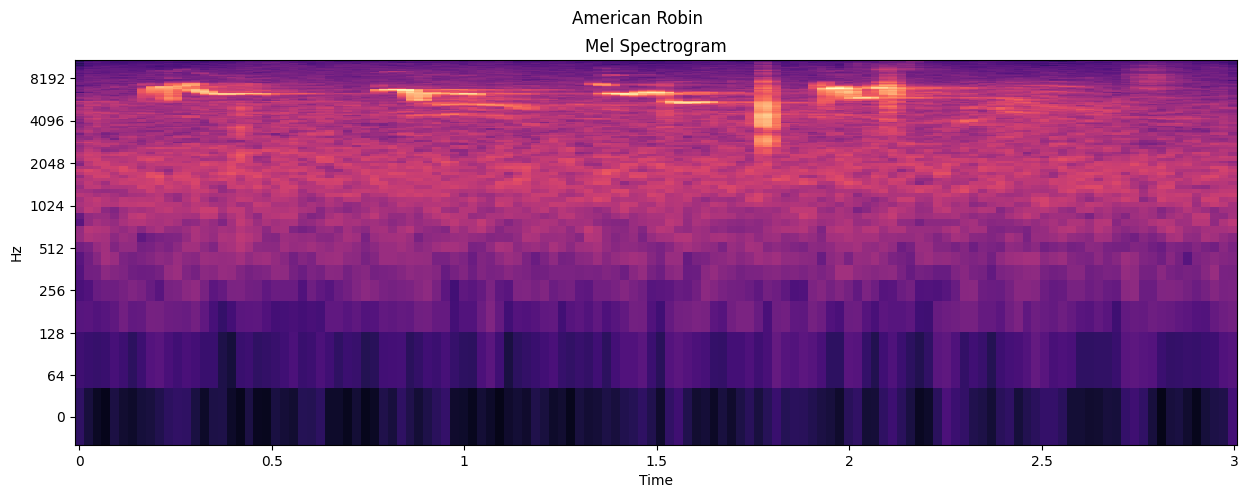

In [8]:
i = np.random.randint(0, df.shape[0])
generate_spectrogram(df.loc[i, "filename"], df.loc[i, "name"])

Plotting waveform

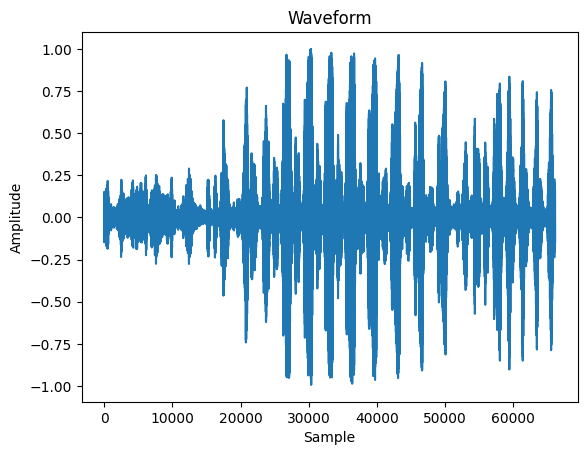

In [9]:
filename = "/kaggle/input/bird-song-data-set/wavfiles/101308-0.wav"
audio_data, sample_rate = librosa.load(filename)

plt.plot(audio_data)
plt.title("Waveform")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.show()

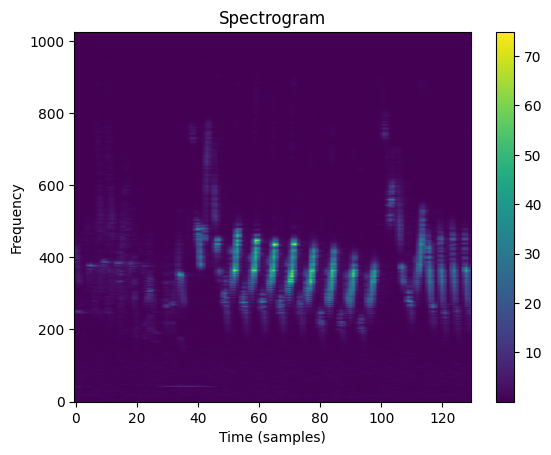

In [10]:
filename ="/kaggle/input/bird-song-data-set/wavfiles/101308-0.wav"
audio_data, sample_rate = librosa.load(filename)
spectrogram = librosa.stft(audio_data)
spectrogram = np.abs(spectrogram)

plt.imshow(spectrogram, origin='lower', aspect='auto')
plt.title("Spectrogram")
plt.xlabel("Time (samples)")
plt.ylabel("Frequency")
plt.colorbar()
plt.show()

Preprocessing function for audio

In [11]:
def process_audio(audio_file):
    audio_data, sample_rate = librosa.load(audio_file, duration=10)
    mel_spec = librosa.feature.melspectrogram(y=audio_data, sr=sample_rate) 
    mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
    return mel_spec

In [12]:
filename = '/kaggle/input/bird-song-data-set/wavfiles/101308-0.wav'
print(len(process_audio(filename)))
print(len(process_audio(filename)[0]))


128
130


Generating a pandas Dataframe to process the data from the CSV and wav files

In [13]:
df_train = pd.DataFrame({"name": df["name"], "audiopath": path_to_wav + df["filename"]})

# Assuming `process_audio` is a function that generates mel spectrograms
df_train["mel_spec"] = df_train["audiopath"].apply(lambda x: process_audio(x))

# Using factorize to encode class labels
df_train["class"] = df_train["name"].factorize()[0]

Shuffle data

In [14]:
from sklearn.utils import shuffle

df_train = shuffle(df_train)
df_train.shape

(5422, 4)

Seperate train and test data

In [15]:
(train_x, train_y) = df_train["mel_spec"][:5000].values, df_train["class"][:5000].values
(test_x, test_y) = df_train["mel_spec"][5000:].values, df_train["class"][5000:].values

In [16]:
from keras.utils import to_categorical

test_y = to_categorical(test_y, num_classes=len(class_names))
train_y = to_categorical(train_y, num_classes=len(class_names))


Normalize data and generate Tensorflow datasets

In [17]:
train_x = np.stack(train_x[:])
test_x = np.stack(test_x[:])

train_x = tf.keras.utils.normalize(train_x)
test_x = tf.keras.utils.normalize(test_x)

train_dataset = tf.data.Dataset.from_tensor_slices((train_x, train_y))
test_dataset = tf.data.Dataset.from_tensor_slices((test_x, test_y))

Setting batch sizes

In [18]:
train_dataset = train_dataset.batch(10)
test_dataset = test_dataset.batch(10)
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

In [19]:
import keras
from keras.layers import Conv2D, MaxPooling2D, BatchNormalization, Flatten, Dense, Reshape, InputLayer, Dropout
from keras.models import Sequential

Setting up model

In [20]:
model = keras.models.Sequential()

model.add(InputLayer(input_shape=(128,130)))
model.add(Reshape((128,130,1)))
model.add(Conv2D(64, (8, 8), input_shape=(128, 130), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(16, (2,2), activation='relu'))
model.add(Flatten())
model.add(Dropout(0.5))
model.add(Dense(128, activation='relu'))
model.add(Dense(5, activation='softmax'))

In [21]:
# model2 = keras.models.Sequential()

# model2.add(InputLayer(input_shape=(128,130)))
# model2.add(Reshape((128,130,1)))
# model2.add(Conv2D(64, (8, 8), input_shape=(128, 130), activation='relu'))
# model2.add(BatchNormalization())
# model2.add(MaxPooling2D(pool_size=(2,2)))
# model2.add(Conv2D(16, (2,2), activation='relu'))
# model2.add(Flatten())
# model2.add(Dropout(0.5))
# model2.add(Dense(128, activation='relu'))
# model2.add(Dense(5, activation='softmax'))

In [22]:
# model3 = keras.models.Sequential()

# model3.add(InputLayer(input_shape=(128,130)))
# model3.add(Reshape((128,130,1)))
# model3.add(Conv2D(64, (8, 8), input_shape=(128, 130), activation='relu'))
# model3.add(BatchNormalization())
# model3.add(MaxPooling2D(pool_size=(2,2)))
# model3.add(Conv2D(16, (2,2), activation='relu'))
# model3.add(Flatten())
# model3.add(Dropout(0.5))
# model3.add(Dense(128, activation='relu'))
# model3.add(Dense(5, activation='softmax'))

In [23]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 reshape (Reshape)           (None, 128, 130, 1)       0         
                                                                 
 conv2d (Conv2D)             (None, 121, 123, 64)      4160      
                                                                 
 batch_normalization (Batch  (None, 121, 123, 64)      256       
 Normalization)                                                  
                                                                 
 max_pooling2d (MaxPooling2  (None, 60, 61, 64)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 59, 60, 16)        4112      
                                                                 
 flatten (Flatten)           (None, 56640)             0

Model compiling

In [24]:
model.compile('adam', loss='categorical_crossentropy', metrics=[tf.keras.metrics.Recall(),tf.keras.metrics.Precision(), 'accuracy'])

In [25]:
# model2.compile('adam', loss='categorical_crossentropy', metrics=[tf.keras.metrics.Recall(),tf.keras.metrics.Precision(), 'accuracy'])

In [26]:
# model3.compile('adam', loss='categorical_crossentropy', metrics=[tf.keras.metrics.Recall(),tf.keras.metrics.Precision(), 'accuracy'])

Model training

In [27]:
hist = model.fit(train_dataset, epochs=50, validation_data=test_dataset)

Epoch 1/50
500/500 [==============================] - 14s 10ms/step - loss: 0.9050 - recall: 0.5160 - precision: 0.7063 - accuracy: 0.6276 - val_loss: 3.3668 - val_recall: 0.2346 - val_precision: 0.2346 - val_accuracy: 0.2346
Epoch 2/50
500/500 [==============================] - 5s 9ms/step - loss: 0.4919 - recall: 0.7806 - precision: 0.8552 - accuracy: 0.8180 - val_loss: 4.4251 - val_recall: 0.4455 - val_precision: 0.4508 - val_accuracy: 0.4502
Epoch 3/50
500/500 [==============================] - 5s 9ms/step - loss: 0.2506 - recall: 0.8946 - precision: 0.9270 - accuracy: 0.9116 - val_loss: 1.8414 - val_recall: 0.6114 - val_precision: 0.6293 - val_accuracy: 0.6232
Epoch 4/50
500/500 [==============================] - 5s 9ms/step - loss: 0.1575 - recall: 0.9438 - precision: 0.9541 - accuracy: 0.9494 - val_loss: 4.7408 - val_recall: 0.5071 - val_precision: 0.5120 - val_accuracy: 0.5095
Epoch 5/50
500/500 [==============================] - 5s 9ms/step - loss: 0.1069 - recall: 0.9626 - pr

In [28]:
# hist2 = model2.fit(train_dataset, epochs=50, validation_data=test_dataset)

In [29]:
# hist3 = model3.fit(train_dataset, epochs=20, validation_data=test_dataset)

Model evaluation on accuracy on test dataset

In [30]:
model.evaluate(test_dataset)

43/43 [==============================] - 0s 5ms/step - loss: 2.2860 - recall: 0.8033 - precision: 0.8052 - accuracy: 0.8057


[2.2859694957733154, 0.8033175468444824, 0.805225670337677, 0.8056871891021729]

In [31]:
# model2.evaluate(test_dataset)

In [32]:
# model3.evaluate(test_dataset)

In [33]:
pred_y = model.predict(test_x)
true_y = test_y.argmax(axis=1, keepdims=True)

14/14 [==============================] - 0s 11ms/step


In [34]:
print(pred_y)
print(true_y)

[[7.3896521e-03 3.4432259e-07 1.4736541e-19 9.9261004e-01 6.8624819e-12]
 [4.2611160e-16 0.0000000e+00 0.0000000e+00 1.0000000e+00 0.0000000e+00]
 [3.8745515e-25 2.6907250e-08 8.8180031e-16 5.2516970e-13 1.0000000e+00]
 ...
 [9.9599010e-01 3.3037385e-04 1.2614524e-03 2.3430344e-03 7.5047239e-05]
 [2.0406985e-28 4.8808892e-22 1.0000000e+00 9.7675305e-31 5.1264174e-30]
 [9.9999964e-01 4.5737364e-18 3.1546383e-19 3.2879041e-07 3.2778934e-17]]
[[3]
 [3]
 [4]
 [0]
 [4]
 [1]
 [2]
 [1]
 [2]
 [3]
 [3]
 [2]
 [3]
 [1]
 [3]
 [0]
 [4]
 [1]
 [3]
 [2]
 [1]
 [2]
 [2]
 [1]
 [3]
 [3]
 [3]
 [3]
 [1]
 [1]
 [3]
 [1]
 [2]
 [4]
 [1]
 [2]
 [2]
 [0]
 [4]
 [4]
 [0]
 [1]
 [2]
 [3]
 [0]
 [2]
 [4]
 [4]
 [4]
 [0]
 [2]
 [3]
 [2]
 [4]
 [1]
 [4]
 [2]
 [4]
 [3]
 [2]
 [4]
 [3]
 [2]
 [4]
 [2]
 [2]
 [3]
 [0]
 [4]
 [4]
 [2]
 [2]
 [4]
 [4]
 [3]
 [4]
 [4]
 [0]
 [3]
 [4]
 [3]
 [3]
 [4]
 [1]
 [1]
 [3]
 [1]
 [2]
 [1]
 [1]
 [1]
 [2]
 [2]
 [1]
 [4]
 [1]
 [1]
 [0]
 [1]
 [3]
 [2]
 [0]
 [1]
 [4]
 [4]
 [2]
 [0]
 [3]
 [3]
 [0]
 [4]
 

Lots of plots

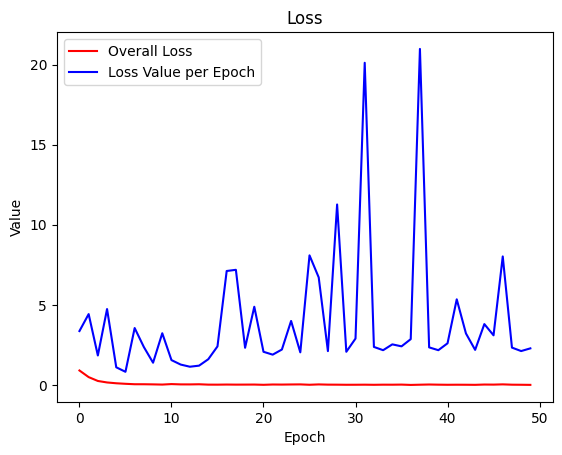

In [35]:
plt.title('Loss')
plt.plot(hist.history['loss'], 'r', label='Overall Loss')
plt.plot(hist.history['val_loss'], 'b', label='Loss Value per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend()
plt.show()

In [36]:
# plt.title('Loss')
# plt.plot(hist.history['loss'], 'r', label='Loss for 100 Epoch model')
# plt.plot(hist2.history['loss'], 'b', label='Loss for 50 Epoch model')
# plt.plot(hist3.history['loss'], 'g', label='Loss for 20 Epoch model')
# plt.xlabel('Epoch')
# plt.ylabel('Value')
# plt.legend()
# plt.show()

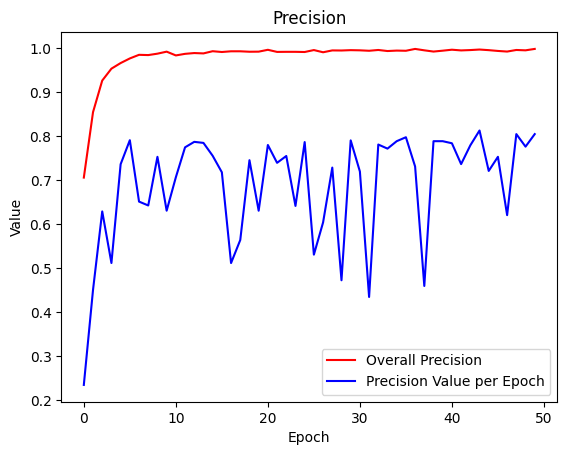

In [37]:
plt.title('Precision')
plt.plot(hist.history['precision'], 'r', label='Overall Precision')
plt.plot(hist.history['val_precision'], 'b', label='Precision Value per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend()
plt.show()

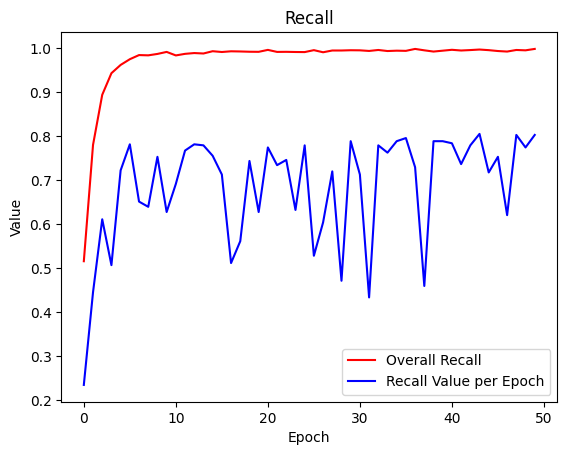

In [38]:
plt.title('Recall')
plt.plot(hist.history['recall'], 'r', label='Overall Recall')
plt.plot(hist.history['val_recall'], 'b', label='Recall Value per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend()
plt.show()

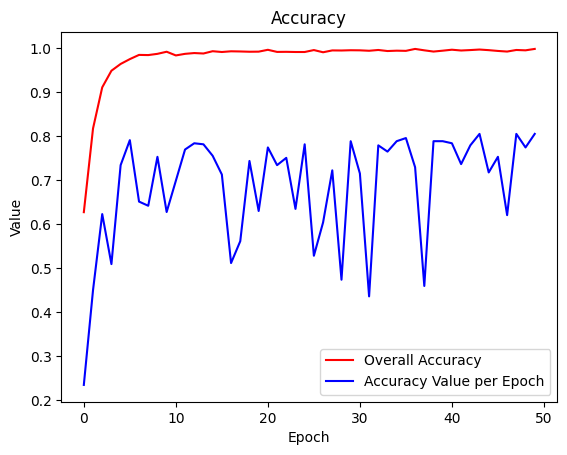

In [39]:
plt.title('Accuracy')
plt.plot(hist.history['accuracy'], 'r', label='Overall Accuracy')
plt.plot(hist.history['val_accuracy'], 'b', label='Accuracy Value per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend()
plt.show()

In [40]:
audio_file = '/kaggle/input/bird-song-data-set/wavfiles/101308-9.wav'
audio_data, sample_rate = librosa.load(audio_file, duration=3)
mel_spec = librosa.feature.melspectrogram(y=audio_data, sr=sample_rate) 
mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
mel_spec = tf.expand_dims(mel_spec, axis=0)
bird_list = ["Bewick's Wren", "Northern Mockingbird", "American Robin", "Song Sparrow", "Northern Cardinal"]

test=model.predict(mel_spec)

print(test)

1/1 [==============================] - 0s 108ms/step
[[0. 0. 0. 1. 0.]]


Generate model file for easy usage later

In [41]:
# from IPython.display import FileLink

# model.save("saved_model") 
# !zip -r saved_model.zip './saved_model' 
# FileLink(r'./saved_model.zip')